# Impacto del trabajo remoto en la salud mental
### Análisis exploratorio de datos (EDA)

## Objetivo
Explorar cómo se relacionan la modalidad de trabajo (remoto, híbrido y presencial), las condiciones laborales y la salud mental de 5,000 empleados, para identificar patrones y posibles grupos en riesgo.

## Datos
- **Archivo:** `Impact_of_Remote_Work_on_Mental_Health.csv`
- **Fuente:** [Remote Work and Mental Health (Kaggle)](https://www.kaggle.com/datasets/waqi786/remote-work-and-mental-health)
- **Tamaño:** 5,000 empleados y 20 variables (demográficas, laborales y de bienestar).

## Preguntas que guían el análisis
**Parte A. Perfil de los trabajadores**
1. ¿Cuál es la distribución de edades, regiones, géneros y puestos?

**Parte B. Vida laboral**
2. ¿Cómo se distribuye la modalidad de trabajo y cuántas horas se trabajan en cada una?
3. ¿Cambian la experiencia y el equilibrio vida-trabajo según la modalidad?
4. ¿Cómo varían el apoyo de la empresa, las reuniones virtuales y las horas según el puesto y la industria?

**Parte C. Salud y bienestar**
5. ¿Qué proporción de trabajadores combina estrés alto con mala calidad de sueño y cómo se ve su productividad?
6. ¿Cómo se distribuyen las condiciones de salud mental según género, edad y nivel de experiencia?

## Índice
0. Configuración
1. Carga y revisión inicial de los datos
2. Limpieza y preparación
3. Parte A. Perfil de los trabajadores
4. Parte B. Vida laboral
5. Parte C. Salud y bienestar
6. Conclusiones y limitaciones

## 0. Configuración
Se importan las librerías una sola vez y se definen dos funciones auxiliares (tablas de frecuencia y gráficos de barras) para mantener el análisis consistente y evitar código repetido.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})
pd.set_option("display.max_columns", 30)

In [2]:
def tabla_frecuencias(columna):
    """Conteo y porcentaje de cada categoría de una columna."""
    conteo = df[columna].value_counts()
    return pd.DataFrame({
        "Trabajadores": conteo,
        "Porcentaje (%)": (conteo / len(df) * 100).round(1),
    })


def grafico_barras(serie, titulo, xlabel="", ylabel="Número de trabajadores",
                   rotacion=0, formato="%d"):
    """Gráfico de barras con etiquetas de valor sobre cada barra."""
    fig, ax = plt.subplots()
    barras = ax.bar(serie.index.astype(str), serie.values, color=sns.color_palette("deep")[0])
    ax.bar_label(barras, fmt=formato, padding=3)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.margins(y=0.12)
    plt.setp(ax.get_xticklabels(), rotation=rotacion, ha="right" if rotacion else "center")
    plt.tight_layout()
    plt.show()


def promedio_por(grupo, variable, decimales=2):
    """Promedio de una variable por grupo, de mayor a menor."""
    return df.groupby(grupo)[variable].mean().round(decimales).sort_values(ascending=False)

## 1. Carga y revisión inicial de los datos

In [3]:
# Ajusta la ruta si el archivo está en otra carpeta (en Google Colab: "/content/<archivo>.csv")
RUTA = "Impact_of_Remote_Work_on_Mental_Health.csv"
df = pd.read_csv(RUTA)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 5,000 | Columnas: 20


,Employee_ID,Age,Gender,Job_Role,Industry,Years_of_Experience,Work_Location,Hours_Worked_Per_Week,Number_of_Virtual_Meetings,Work_Life_Balance_Rating,Stress_Level,Mental_Health_Condition,Access_to_Mental_Health_Resources,Productivity_Change,Social_Isolation_Rating,Satisfaction_with_Remote_Work,Company_Support_for_Remote_Work,Physical_Activity,Sleep_Quality,Region
0,EMP0001,32,Non-binary,HR,Healthcare,13,Hybrid,47,7,2,Medium,Depression,No,Decrease,1,Unsatisfied,1,Weekly,Good,Europe
1,EMP0002,40,Female,Data Scientist,IT,3,Remote,52,4,1,Medium,Anxiety,No,Increase,3,Satisfied,2,Weekly,Good,Asia
2,EMP0003,59,Non-binary,Software Engineer,Education,22,Hybrid,46,11,5,Medium,Anxiety,No,No Change,4,Unsatisfied,5,NaN,Poor,North America
3,EMP0004,27,Male,Software Engineer,Finance,20,Onsite,32,8,4,High,Depression,Yes,Increase,3,Unsatisfied,3,NaN,Poor,Europe
4,EMP0005,49,Male,Sales,Consulting,32,Onsite,35,12,2,High,NaN,Yes,Decrease,3,Unsatisfied,3,Weekly,Average,North America


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Employee_ID                        5000 non-null   str  
 1   Age                                5000 non-null   int64
 2   Gender                             5000 non-null   str  
 3   Job_Role                           5000 non-null   str  
 4   Industry                           5000 non-null   str  
 5   Years_of_Experience                5000 non-null   int64
 6   Work_Location                      5000 non-null   str  
 7   Hours_Worked_Per_Week              5000 non-null   int64
 8   Number_of_Virtual_Meetings         5000 non-null   int64
 9   Work_Life_Balance_Rating           5000 non-null   int64
 10  Stress_Level                       5000 non-null   str  
 11  Mental_Health_Condition            3804 non-null   str  
 12  Access_to_Mental_Health_Resourc

In [5]:
df.describe().round(2)

,Age,Years_of_Experience,Hours_Worked_Per_Week,Number_of_Virtual_Meetings,Work_Life_Balance_Rating,Social_Isolation_Rating,Company_Support_for_Remote_Work
count,5000.0,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,41.0,17.81,39.61,7.56,2.98,2.99,3.01
std,11.3,10.02,11.86,4.64,1.41,1.39,1.40
min,22.0,1.00,20.00,0.00,1.00,1.00,1.00
25%,31.0,9.00,29.00,4.00,2.00,2.00,2.00
50%,41.0,18.00,40.00,8.00,3.00,3.00,3.00
75%,51.0,26.00,50.00,12.00,4.00,4.00,4.00
max,60.0,35.00,60.00,15.00,5.00,5.00,5.00


## 2. Limpieza y preparación

### 2.1 Valores nulos y duplicados

In [6]:
nulos = df.isnull().sum()
tabla_nulos = pd.DataFrame({"Nulos": nulos, "% del total": (nulos / len(df) * 100).round(1)})
print("Variables con valores nulos:")
display(tabla_nulos[tabla_nulos["Nulos"] > 0])

print(f"\nID de empleado únicos: {df['Employee_ID'].is_unique}")
print(f"Filas duplicadas: {df.duplicated().sum()}")

Variables con valores nulos:


,Nulos,% del total
Mental_Health_Condition,1196,23.9
Physical_Activity,1629,32.6



ID de empleado únicos: True
Filas duplicadas: 0


Solo dos variables tienen nulos: `Mental_Health_Condition` (1,196 casos, 23.9%) y `Physical_Activity` (1,629 casos, 32.6%).

### 2.2 Tratamiento de nulos

**`Mental_Health_Condition`:** los nulos se rellenan con la categoría **"Sin condición reportada"**, no con la moda.

> **Decisión metodológica.** Antes de imputar, las tres condiciones tenían frecuencias casi iguales: Burnout 1,280, Ansiedad 1,278 y Depresión 1,246 (más 1,196 nulos). Rellenar los nulos con la moda (Burnout) habría subido Burnout a 2,476 casos, casi el doble de las otras dos condiciones, **creando un patrón que no existe en los datos originales**. Como un nulo en esta variable probablemente significa que la persona no reportó ninguna condición, se conserva como una categoría propia.

**`Physical_Activity`:** los nulos se rellenan con **"No reportado"** para no perder esos registros ni distorsionar las categorías `Daily` y `Weekly`.

In [7]:
df["Mental_Health_Condition"] = df["Mental_Health_Condition"].fillna("Sin condición reportada")
df["Physical_Activity"] = df["Physical_Activity"].fillna("No reportado")

print("Nulos restantes:", int(df.isnull().sum().sum()))
tabla_frecuencias("Mental_Health_Condition")

Nulos restantes: 0


,Trabajadores,Porcentaje (%)
Mental_Health_Condition,,
Burnout,1280,25.6
Anxiety,1278,25.6
Depression,1246,24.9
Sin condición reportada,1196,23.9


### 2.3 Variables derivadas
- **`Nivel_Experiencia`:** *Junior* (menos de 10 años de experiencia) o *Senior* (10 años o más).
- **`Stress_Level_Numeric`** y **`Sleep_Quality_Numeric`:** versiones numéricas de las categorías de estrés (Low=1, Medium=2, High=3) y de calidad de sueño (Poor=1, Average=2, Good=3).
- **`Rango_Edad`:** grupos de edad de 10 años (20-29, 30-39, 40-49 y 50-60).

In [8]:
df["Nivel_Experiencia"] = np.where(df["Years_of_Experience"] < 10, "Junior", "Senior")

df["Stress_Level_Numeric"] = df["Stress_Level"].map({"Low": 1, "Medium": 2, "High": 3})
df["Sleep_Quality_Numeric"] = df["Sleep_Quality"].map({"Poor": 1, "Average": 2, "Good": 3})

# right=False -> los intervalos incluyen el límite inferior: [20,30), [30,40), [40,50), [50,61)
df["Rango_Edad"] = pd.cut(df["Age"], bins=[20, 30, 40, 50, 61],
                          labels=["20-29", "30-39", "40-49", "50-60"], right=False)

# Control: ninguna transformación debe generar nulos
assert df[["Stress_Level_Numeric", "Sleep_Quality_Numeric", "Rango_Edad"]].notna().all().all()
tabla_frecuencias("Nivel_Experiencia")

,Trabajadores,Porcentaje (%)
Nivel_Experiencia,,
Senior,3682,73.6
Junior,1318,26.4


Los trabajadores **Senior** son mayoría porque la experiencia va de 1 a 35 años y el corte está en 10. Por eso, más adelante las comparaciones entre Junior y Senior se hacen con **porcentajes dentro de cada grupo** y no con conteos absolutos.

## 3. Parte A. Perfil de los trabajadores

### 3.1 Distribución de edades

count    5000.0
mean       41.0
std        11.3
min        22.0
25%        31.0
50%        41.0
75%        51.0
max        60.0
Name: Age, dtype: float64


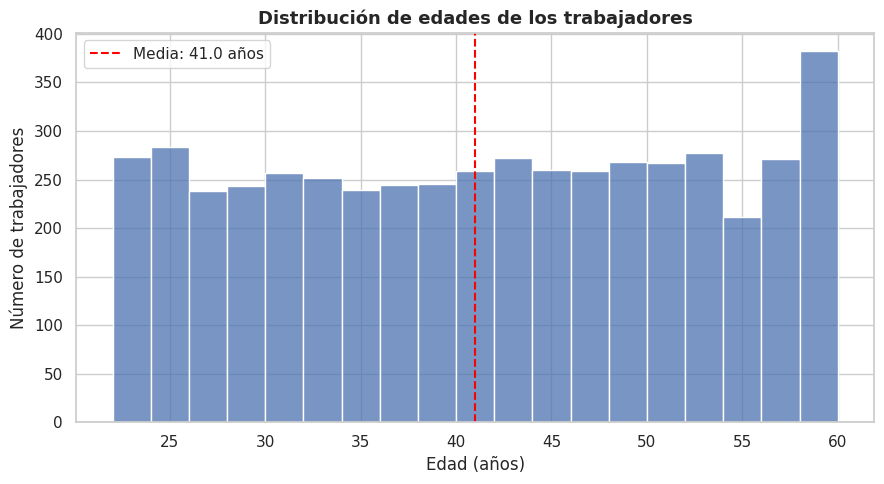

In [9]:
print(df["Age"].describe().round(1))

fig, ax = plt.subplots()
sns.histplot(df["Age"], bins=19, ax=ax)
ax.axvline(df["Age"].mean(), color="red", linestyle="--", label=f"Media: {df['Age'].mean():.1f} años")
ax.set_title("Distribución de edades de los trabajadores")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Número de trabajadores")
ax.legend()
plt.tight_layout()
plt.show()

Las edades van de **22 a 60 años**, con una media y mediana de **41 años**.

### 3.2 Distribución geográfica

In [10]:
tabla_frecuencias("Region")

,Trabajadores,Porcentaje (%)
Region,,
Oceania,867,17.3
Africa,860,17.2
Europe,840,16.8
Asia,829,16.6
South America,827,16.5
North America,777,15.5


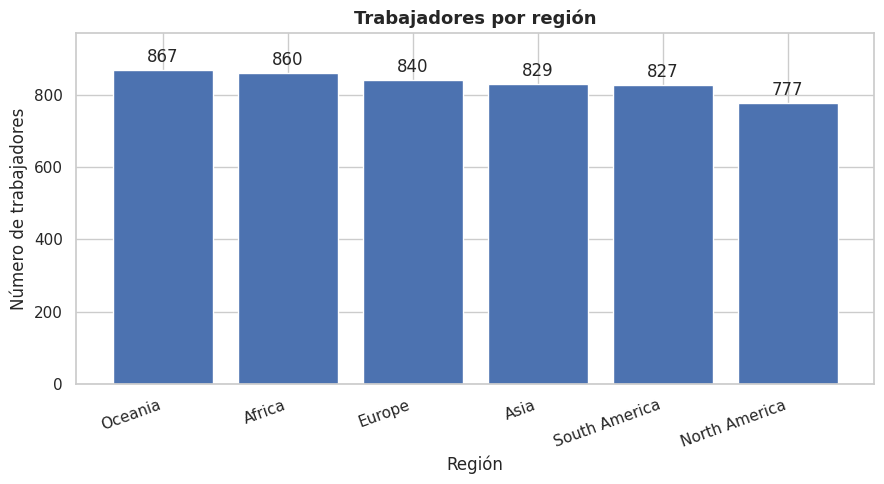

In [11]:
grafico_barras(df["Region"].value_counts(), "Trabajadores por región", "Región", rotacion=20)

La muestra está muy equilibrada entre regiones: Oceanía es la más numerosa (**17.3%**) y Norteamérica la menos (**15.5%**).

### 3.3 Distribución por género

In [12]:
tabla_frecuencias("Gender")

,Trabajadores,Porcentaje (%)
Gender,,
Female,1274,25.5
Male,1270,25.4
Prefer not to say,1242,24.8
Non-binary,1214,24.3


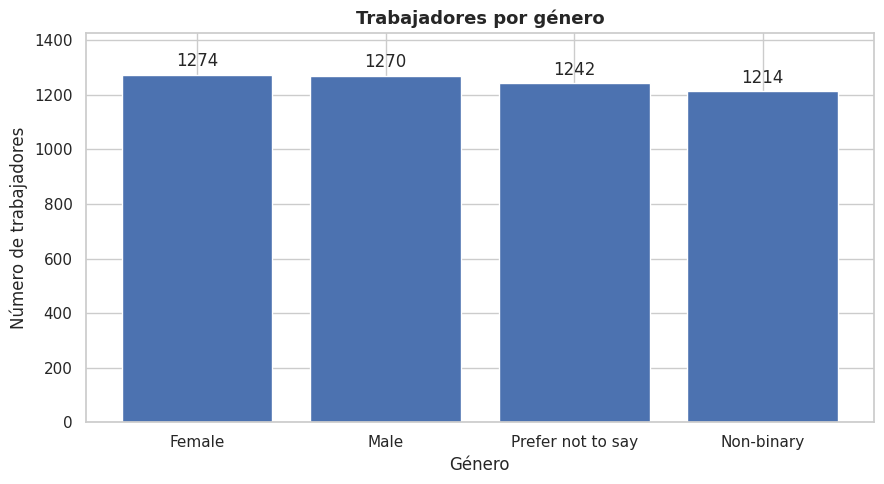

In [13]:
grafico_barras(df["Gender"].value_counts(), "Trabajadores por género", "Género")

Los cuatro grupos de género representan cerca del **25%** cada uno (de 24.3% a 25.5%). Hay 4 mujeres más que hombres (1,274 frente a 1,270).

### 3.4 Puestos de trabajo

In [14]:
tabla_frecuencias("Job_Role")

,Trabajadores,Porcentaje (%)
Job_Role,,
Project Manager,738,14.8
Sales,733,14.7
Designer,723,14.5
HR,716,14.3
Software Engineer,711,14.2
Data Scientist,696,13.9
Marketing,683,13.7


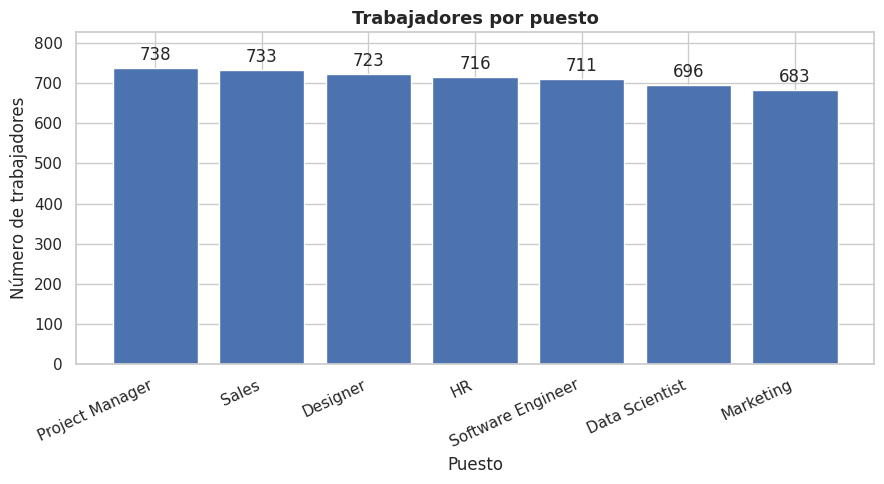

In [15]:
grafico_barras(df["Job_Role"].value_counts(), "Trabajadores por puesto", "Puesto", rotacion=25)

Los siete puestos tienen una representación similar, entre **13.7%** (Marketing) y **14.8%** (Project Manager).

## 4. Parte B. Vida laboral

### 4.1 Modalidad de trabajo

In [16]:
tabla_frecuencias("Work_Location")

,Trabajadores,Porcentaje (%)
Work_Location,,
Remote,1714,34.3
Hybrid,1649,33.0
Onsite,1637,32.7


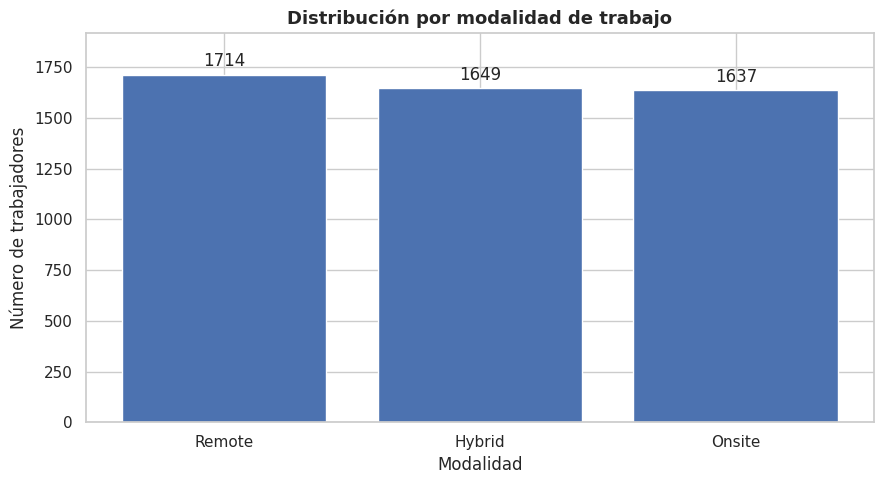

In [17]:
grafico_barras(df["Work_Location"].value_counts(), "Distribución por modalidad de trabajo",
               "Modalidad")

Las tres modalidades tienen un tamaño parecido: remoto (1,714), híbrido (1,649) y presencial (1,637).

### 4.2 Horas semanales según la modalidad

,Horas semanales (promedio)
Work_Location,
Onsite,39.82
Hybrid,39.59
Remote,39.45


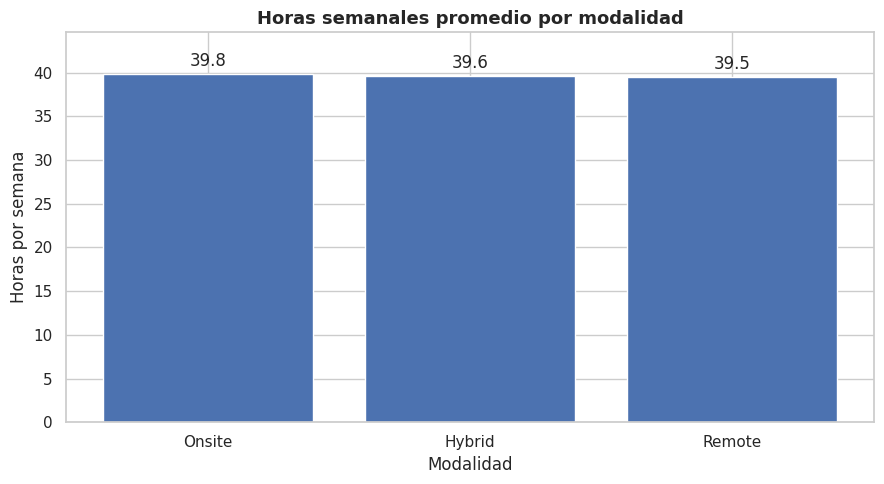

In [18]:
horas_modalidad = promedio_por("Work_Location", "Hours_Worked_Per_Week")
display(horas_modalidad.to_frame("Horas semanales (promedio)"))
grafico_barras(horas_modalidad, "Horas semanales promedio por modalidad", "Modalidad",
               ylabel="Horas por semana", formato="%.1f")

Las horas trabajadas son casi idénticas en las tres modalidades: **entre 39.5 y 39.8 horas por semana**.

### 4.3 Experiencia y equilibrio vida-trabajo según la modalidad

In [19]:
(df.groupby("Work_Location")
   .agg(Experiencia_promedio=("Years_of_Experience", "mean"),
        Equilibrio_vida_trabajo=("Work_Life_Balance_Rating", "mean"))
   .round(2))

,Experiencia_promedio,Equilibrio_vida_trabajo
Work_Location,,
Hybrid,18.01,3.02
Onsite,17.72,2.95
Remote,17.70,2.98


Las diferencias son **mínimas**. Los trabajadores híbridos tienen un poco más de experiencia (18.0 años frente a 17.7) y los presenciales un equilibrio vida-trabajo ligeramente menor (2.95 frente a 3.02 en híbrido), pero con diferencias tan pequeñas no es posible afirmar que la modalidad influya en estas variables.

### 4.4 Apoyo de la empresa al trabajo remoto según el puesto

,Apoyo de la empresa (promedio)
Job_Role,
Data Scientist,3.10
Software Engineer,3.02
Marketing,3.02
Project Manager,3.01
HR,3.01
Sales,2.97
Designer,2.93


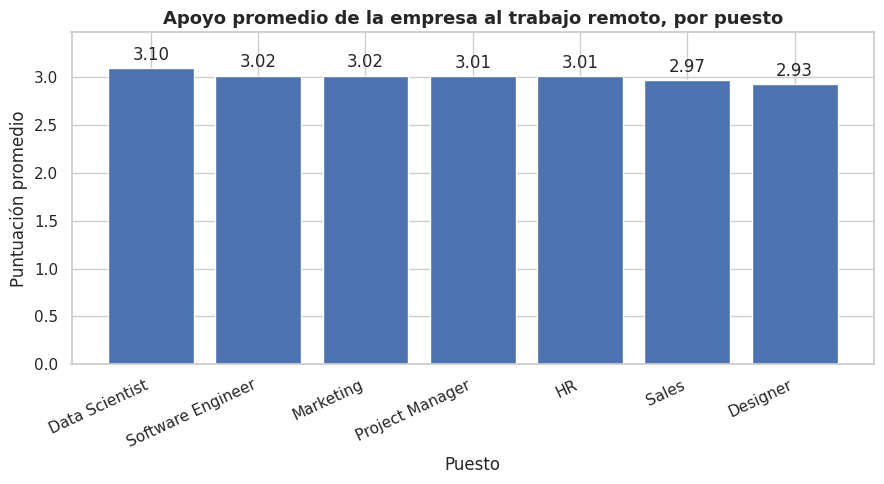

In [20]:
apoyo_puesto = promedio_por("Job_Role", "Company_Support_for_Remote_Work")
display(apoyo_puesto.to_frame("Apoyo de la empresa (promedio)"))
grafico_barras(apoyo_puesto, "Apoyo promedio de la empresa al trabajo remoto, por puesto",
               "Puesto", ylabel="Puntuación promedio", rotacion=25, formato="%.2f")

**Data Scientist** recibe el mayor apoyo (3.10) y **Designer** el menor (2.93), aunque la diferencia entre todos los puestos es pequeña (de 2.93 a 3.10).

### 4.5 Reuniones virtuales según la industria

,Reuniones virtuales (promedio)
Industry,
Healthcare,7.9
Finance,7.7
Consulting,7.6
Manufacturing,7.5
IT,7.5
Retail,7.5
Education,7.2


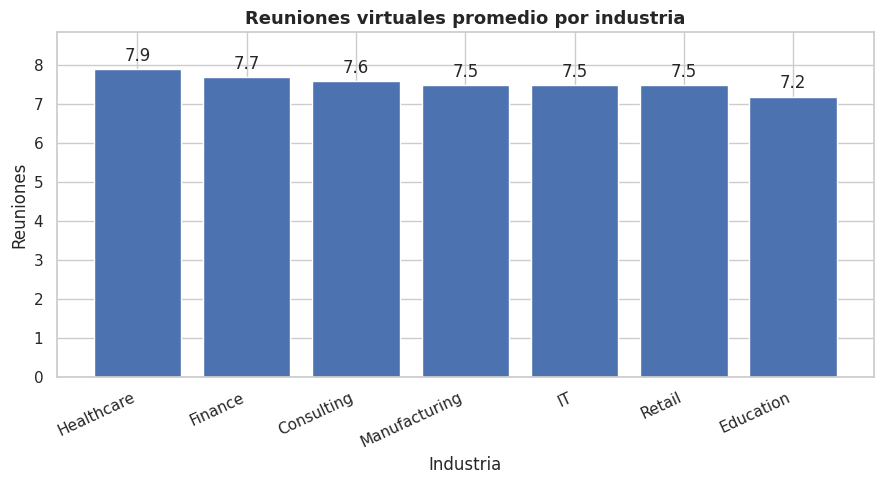

In [21]:
reuniones_industria = promedio_por("Industry", "Number_of_Virtual_Meetings", decimales=1)
display(reuniones_industria.to_frame("Reuniones virtuales (promedio)"))
grafico_barras(reuniones_industria, "Reuniones virtuales promedio por industria", "Industria",
               ylabel="Reuniones", rotacion=25, formato="%.1f")

**Healthcare** tiene el promedio más alto de reuniones virtuales (7.9), seguida de **Finance** (7.7) y **Consulting** (7.6). **Education** tiene el más bajo (7.2).

### 4.6 Horas semanales según la industria

,Horas semanales (promedio)
Industry,
Manufacturing,40.2
Healthcare,40.1
IT,40.0
Education,39.4
Consulting,39.2
Finance,39.2
Retail,39.2


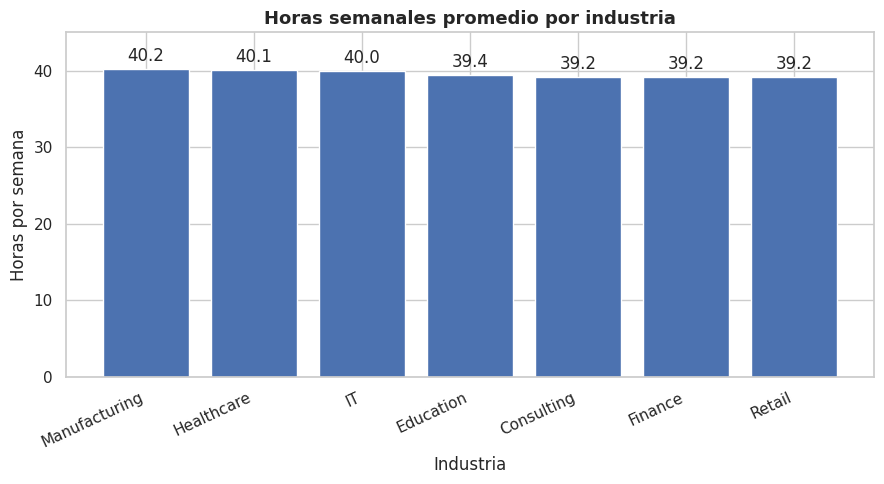

In [22]:
horas_industria = promedio_por("Industry", "Hours_Worked_Per_Week", decimales=1)
display(horas_industria.to_frame("Horas semanales (promedio)"))
grafico_barras(horas_industria, "Horas semanales promedio por industria", "Industria",
               ylabel="Horas por semana", rotacion=25, formato="%.1f")

Las horas semanales son muy similares entre industrias (de 39.2 a 40.2). **Manufacturing** es la que más horas trabaja (40.2), seguida de Healthcare (40.1) e IT (40.0).

## 5. Parte C. Salud y bienestar

### 5.1 Grupo en riesgo: estrés alto y mala calidad de sueño
Se identifica a los trabajadores con **estrés alto** y **mala calidad de sueño** al mismo tiempo, y se compara su productividad con la del resto.

In [23]:
en_riesgo = (df["Stress_Level_Numeric"] == 3) & (df["Sleep_Quality_Numeric"] == 1)
df["Grupo_Riesgo"] = np.where(en_riesgo, "Estrés alto + mal sueño", "Resto")

n_riesgo = int(en_riesgo.sum())
print(f"Trabajadores con estrés alto y mala calidad de sueño: {n_riesgo:,} de {len(df):,} "
      f"({n_riesgo / len(df) * 100:.1f}%)")

columnas_clave = ["Age", "Gender", "Work_Location", "Job_Role", "Industry",
                  "Stress_Level", "Sleep_Quality", "Productivity_Change"]
df.loc[en_riesgo, columnas_clave].head(5)

Trabajadores con estrés alto y mala calidad de sueño: 584 de 5,000 (11.7%)


,Age,Gender,Work_Location,Job_Role,Industry,Stress_Level,Sleep_Quality,Productivity_Change
3,27,Male,Onsite,Software Engineer,Finance,High,Poor,Increase
8,56,Prefer not to say,Hybrid,Data Scientist,Healthcare,High,Poor,Decrease
26,36,Non-binary,Onsite,Project Manager,Retail,High,Poor,Decrease
28,47,Prefer not to say,Onsite,Sales,IT,High,Poor,Decrease
29,59,Male,Remote,Software Engineer,Healthcare,High,Poor,No Change


Productivity_Change,Decrease,Increase,No Change
Grupo_Riesgo,,,
Estrés alto + mal sueño,36.3,35.1,28.6
Resto,34.5,31.3,34.2


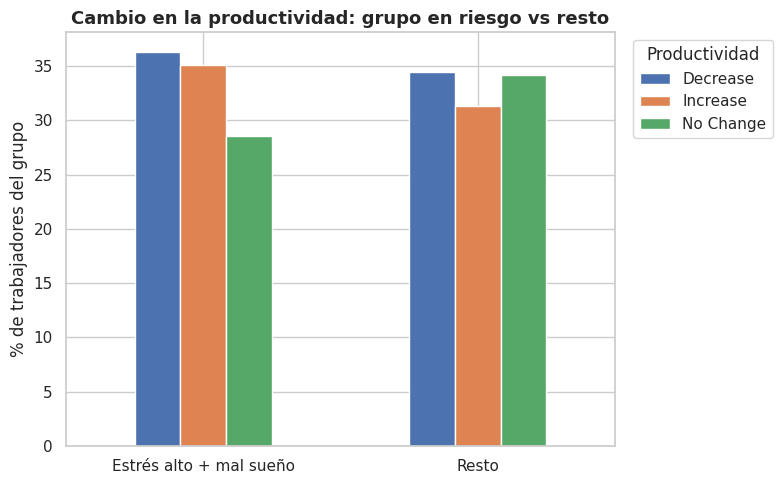

Reportó disminución de productividad: 36.3% en el grupo en riesgo frente a 34.5% en el resto.
Chi-cuadrado = 7.67 | valor p = 0.0216


In [24]:
# Cambio en la productividad: % dentro de cada grupo
productividad = (pd.crosstab(df["Grupo_Riesgo"], df["Productivity_Change"], normalize="index")
                   .mul(100).round(1))
display(productividad)

ax = productividad.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_title("Cambio en la productividad: grupo en riesgo vs resto")
ax.set_xlabel("")
ax.set_ylabel("% de trabajadores del grupo")
ax.legend(title="Productividad", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

dec_riesgo = productividad.loc["Estrés alto + mal sueño", "Decrease"]
dec_resto = productividad.loc["Resto", "Decrease"]
print(f"Reportó disminución de productividad: {dec_riesgo:.1f}% en el grupo en riesgo "
      f"frente a {dec_resto:.1f}% en el resto.")

# ¿La distribución de productividad difiere entre ambos grupos? (chi-cuadrado)
chi2, p, gl, _ = chi2_contingency(pd.crosstab(df["Grupo_Riesgo"], df["Productivity_Change"]))
print(f"Chi-cuadrado = {chi2:.2f} | valor p = {p:.4f}")

**¿El problema se concentra en algún tipo de trabajador?** Se calcula qué porcentaje de cada modalidad e industria pertenece al grupo en riesgo.

In [25]:
for columna in ["Work_Location", "Industry"]:
    porcentaje = (df.groupby(columna)["Grupo_Riesgo"]
                    .apply(lambda s: (s == "Estrés alto + mal sueño").mean() * 100)
                    .round(1).sort_values(ascending=False))
    display(porcentaje.to_frame(f"% en grupo de riesgo por {columna}"))

print("Rango de edad del grupo en riesgo:",
      f"{df.loc[en_riesgo, 'Age'].min()} a {df.loc[en_riesgo, 'Age'].max()} años")

,% en grupo de riesgo por Work_Location
Work_Location,
Hybrid,12.0
Remote,11.6
Onsite,11.5


,% en grupo de riesgo por Industry
Industry,
Finance,13.3
Consulting,11.9
Education,11.6
Retail,11.4
Manufacturing,11.4
Healthcare,11.1
IT,11.0


Rango de edad del grupo en riesgo: 22 a 60 años


**Lectura.** Los 584 trabajadores del grupo en riesgo (11.7%) se distribuyen de forma pareja entre modalidades (11.5% a 12.0%), industrias (11.0% a 13.3%) y edades (22 a 60 años): el problema **no se concentra** en un tipo de trabajador. En productividad, el 36.3% del grupo en riesgo reportó una disminución frente al 34.5% del resto, una diferencia de solo 1.8 puntos. La distribución completa sí difiere de forma estadísticamente significativa (p = 0.02), pero principalmente porque en el grupo en riesgo hay **menos personas sin cambio** (28.6% vs 34.2%) y **más personas que reportan un aumento** (35.1% vs 31.3%). Estos datos no respaldan que el estrés alto con mal sueño se traduzca en menor productividad.

### 5.2 Condiciones de salud mental según el género
Se muestra el **porcentaje dentro de cada género** para poder comparar grupos de distinto tamaño.

Número de trabajadores:


Mental_Health_Condition,Burnout,Anxiety,Depression,Sin condición reportada
Gender,,,,
Female,327,311,321,315
Male,336,324,334,276
Non-binary,301,305,311,297
Prefer not to say,316,338,280,308


Porcentaje dentro de cada género:


Mental_Health_Condition,Burnout,Anxiety,Depression,Sin condición reportada
Gender,,,,
Female,25.7,24.4,25.2,24.7
Male,26.5,25.5,26.3,21.7
Non-binary,24.8,25.1,25.6,24.5
Prefer not to say,25.4,27.2,22.5,24.8


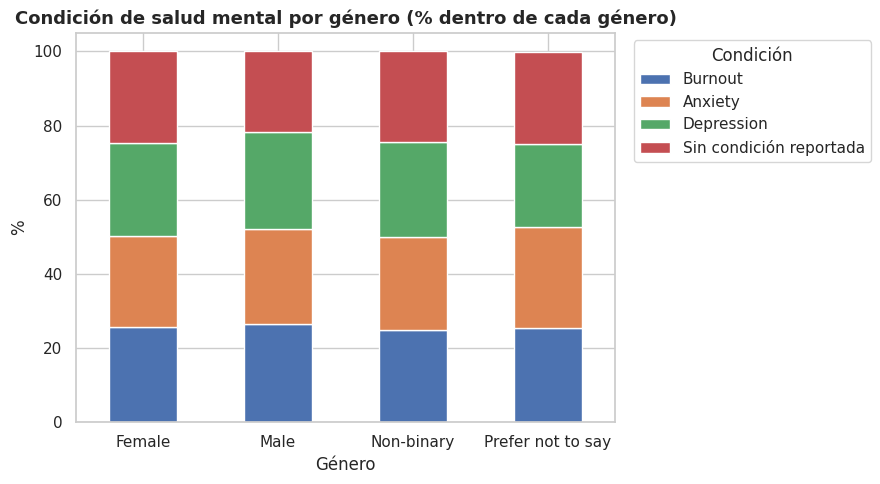

Diferencia máxima entre géneros (en puntos porcentuales):
Mental_Health_Condition
Burnout                    1.7
Anxiety                    2.8
Depression                 3.8
Sin condición reportada    3.1


In [26]:
orden_condiciones = ["Burnout", "Anxiety", "Depression", "Sin condición reportada"]

conteo_genero = pd.crosstab(df["Gender"], df["Mental_Health_Condition"])[orden_condiciones]
pct_genero = (pd.crosstab(df["Gender"], df["Mental_Health_Condition"], normalize="index")
                .mul(100).round(1)[orden_condiciones])

print("Número de trabajadores:")
display(conteo_genero)
print("Porcentaje dentro de cada género:")
display(pct_genero)

ax = pct_genero.plot(kind="bar", stacked=True, figsize=(9, 5), rot=0)
ax.set_title("Condición de salud mental por género (% dentro de cada género)")
ax.set_xlabel("Género")
ax.set_ylabel("%")
ax.legend(title="Condición", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

diferencias = (pct_genero.max() - pct_genero.min()).round(1)
print("Diferencia máxima entre géneros (en puntos porcentuales):")
print(diferencias.to_string())

**Lectura.** En los cuatro géneros, cada condición ronda el 25% (de 21.7% a 27.2%), con diferencias máximas de entre 1.7 y 3.8 puntos porcentuales entre géneros.

### 5.3 Condiciones de salud mental según el rango de edad

Mental_Health_Condition,Burnout,Anxiety,Depression,Sin condición reportada
Rango_Edad,,,,
20-29,26.2,26.3,23.8,23.6
30-39,24.5,24.2,26.8,24.5
40-49,26.3,26.3,24.6,22.8
50-60,25.5,25.5,24.4,24.6


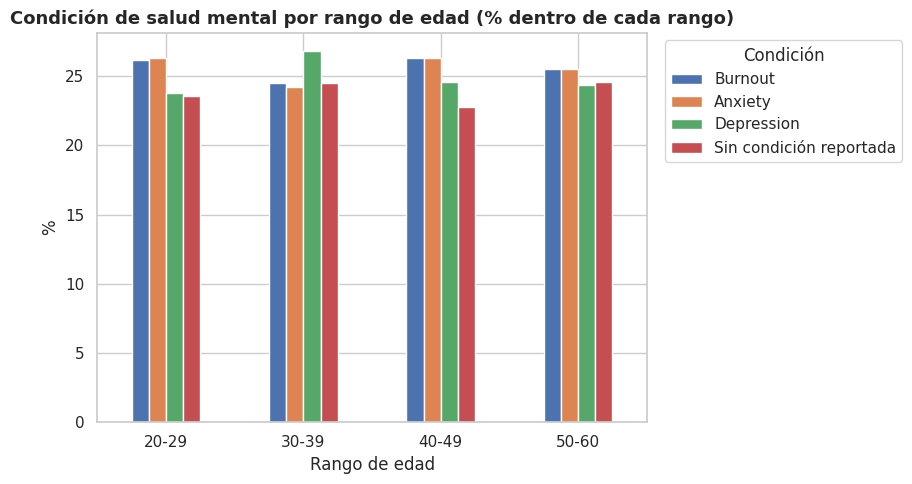

In [27]:
pct_edad = (pd.crosstab(df["Rango_Edad"], df["Mental_Health_Condition"], normalize="index")
              .mul(100).round(1)[orden_condiciones])
display(pct_edad)

ax = pct_edad.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Condición de salud mental por rango de edad (% dentro de cada rango)")
ax.set_xlabel("Rango de edad")
ax.set_ylabel("%")
ax.legend(title="Condición", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Lectura.** Los porcentajes por condición son muy parecidos en todos los rangos de edad (de 22.8% a 26.8%). Ningún rango destaca como más vulnerable.

### 5.4 Condiciones de salud mental: Junior vs Senior
Como los Senior son mayoría, comparar conteos absolutos sería engañoso. Se comparan los **porcentajes dentro de cada nivel**.

Mental_Health_Condition,Burnout,Anxiety,Depression,Sin condición reportada
Nivel_Experiencia,,,,
Junior,25.0,26.3,25.6,23.0
Senior,25.8,25.3,24.7,24.3


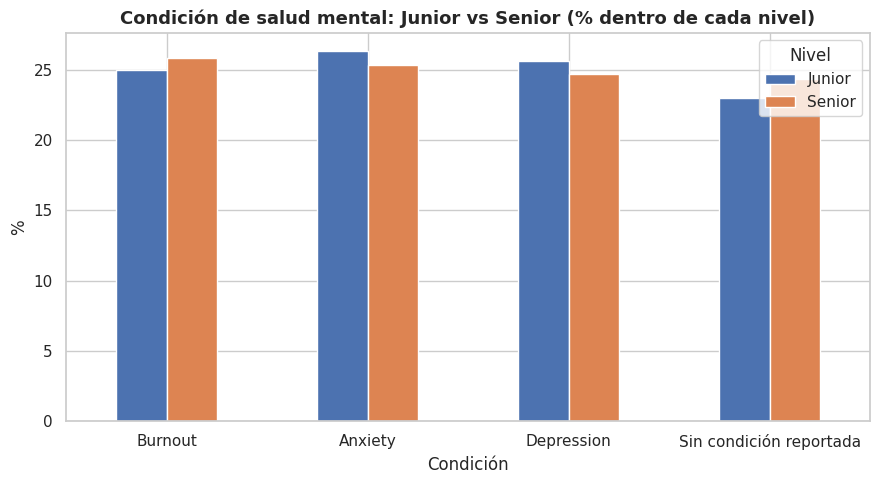

In [28]:
pct_nivel = (pd.crosstab(df["Nivel_Experiencia"], df["Mental_Health_Condition"], normalize="index")
               .mul(100).round(1)[orden_condiciones])
display(pct_nivel)

ax = pct_nivel.T.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Condición de salud mental: Junior vs Senior (% dentro de cada nivel)")
ax.set_xlabel("Condición")
ax.set_ylabel("%")
ax.legend(title="Nivel")
plt.tight_layout()
plt.show()

**Lectura.** Junior y Senior tienen distribuciones casi idénticas (por ejemplo, Burnout 25.0% vs 25.8%). Los Senior no están más afectados: tenían más casos solo porque son más numerosos (73.6% de la muestra).

### 5.5 ¿Las diferencias son estadísticamente relevantes?
Se aplica una prueba **chi-cuadrado de independencia** entre la condición de salud mental y cada variable. Si el valor *p* es mayor que 0.05, no hay evidencia de que la diferencia observada sea más que variación del azar.

In [29]:
resultados = []
for variable in ["Gender", "Rango_Edad", "Nivel_Experiencia"]:
    tabla = pd.crosstab(df[variable], df["Mental_Health_Condition"])
    chi2, p, gl, _ = chi2_contingency(tabla)
    resultados.append({"Variable": variable, "Chi-cuadrado": round(chi2, 2),
                       "Grados de libertad": gl, "Valor p": round(p, 4),
                       "¿Asociación significativa (p < 0.05)?": "Sí" if p < 0.05 else "No"})
pd.DataFrame(resultados)

,Variable,Chi-cuadrado,Grados de libertad,Valor p,¿Asociación significativa (p < 0.05)?
0,Gender,10.26,9,0.3297,No
1,Rango_Edad,6.19,9,0.7212,No
2,Nivel_Experiencia,1.66,3,0.6461,No


### 5.6 Horas trabajadas: Junior vs Senior

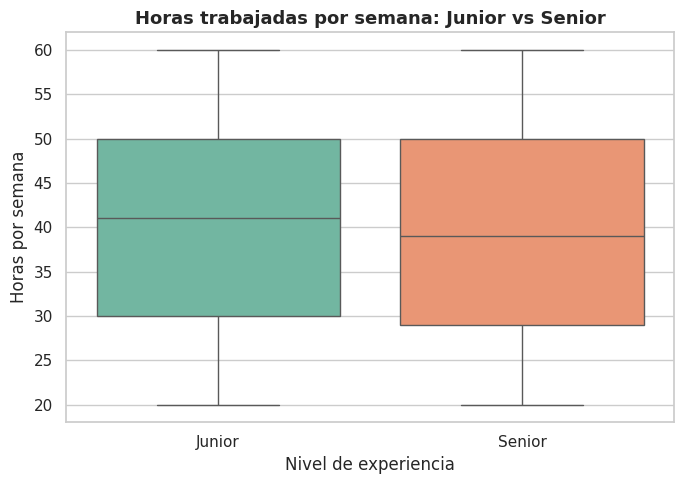

,mean,median
Nivel_Experiencia,,
Junior,40.2,41.0
Senior,39.4,39.0


Prueba t de Welch: valor p = 0.0461


In [30]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="Nivel_Experiencia", y="Hours_Worked_Per_Week",
            hue="Nivel_Experiencia", order=["Junior", "Senior"], hue_order=["Junior", "Senior"],
            palette="Set2", legend=False, ax=ax)
ax.set_title("Horas trabajadas por semana: Junior vs Senior")
ax.set_xlabel("Nivel de experiencia")
ax.set_ylabel("Horas por semana")
plt.tight_layout()
plt.show()

display(df.groupby("Nivel_Experiencia")["Hours_Worked_Per_Week"].agg(["mean", "median"]).round(1))

# Prueba t de Welch para comparar las horas promedio de ambos grupos
junior = df.loc[df["Nivel_Experiencia"] == "Junior", "Hours_Worked_Per_Week"]
senior = df.loc[df["Nivel_Experiencia"] == "Senior", "Hours_Worked_Per_Week"]
print(f"Prueba t de Welch: valor p = {ttest_ind(junior, senior, equal_var=False).pvalue:.4f}")

**Lectura.** Los Junior trabajan en promedio 40.2 horas por semana y los Senior 39.4: una diferencia de menos de una hora. La prueba t da un valor p cercano al límite de 0.05, por lo que se considera una diferencia pequeña y poco concluyente.

### 5.7 Nivel de estrés: Junior vs Senior
`Stress_Level` es una variable **categórica** (Low, Medium, High), por lo que un boxplot no es la herramienta adecuada. Se compara el porcentaje de cada nivel de estrés dentro de cada grupo.

Stress_Level,Low,Medium,High
Nivel_Experiencia,,,
Junior,32.8,33.5,33.8
Senior,32.9,33.4,33.7


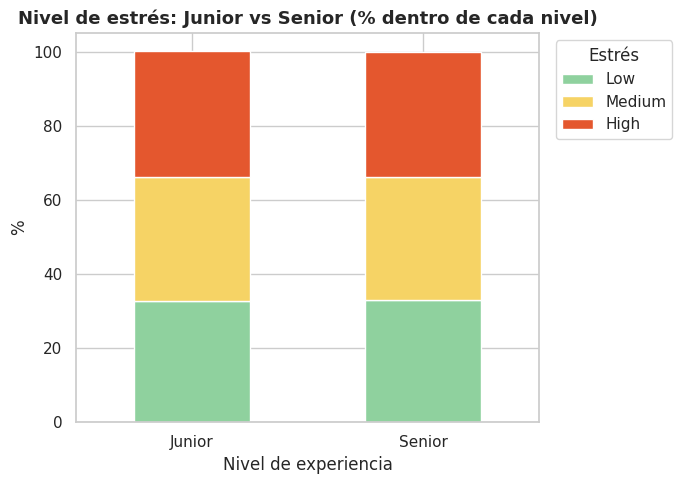

Estrés promedio (1 = bajo, 3 = alto):
Nivel_Experiencia
Junior    2.01
Senior    2.01


In [31]:
pct_estres = (pd.crosstab(df["Nivel_Experiencia"], df["Stress_Level"], normalize="index")
                .mul(100).round(1)[["Low", "Medium", "High"]])
display(pct_estres)

ax = pct_estres.plot(kind="bar", stacked=True, figsize=(7, 5), rot=0,
                     color=["#8fd19e", "#f6d365", "#e4572e"])
ax.set_title("Nivel de estrés: Junior vs Senior (% dentro de cada nivel)")
ax.set_xlabel("Nivel de experiencia")
ax.set_ylabel("%")
ax.legend(title="Estrés", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Estrés promedio (1 = bajo, 3 = alto):")
print(df.groupby("Nivel_Experiencia")["Stress_Level_Numeric"].mean().round(2).to_string())

## 6. Conclusiones y limitaciones

### Hallazgos principales
1. **Muestra equilibrada.** Los 5,000 trabajadores se reparten de forma casi pareja entre géneros (cerca de 25% cada uno), regiones (15.5% a 17.3%), puestos (13.7% a 14.8%) y modalidades de trabajo. Las edades van de 22 a 60 años (media de 41).
2. **La modalidad de trabajo casi no cambia las condiciones laborales.** Las horas semanales (39.5 a 39.8), la experiencia y el equilibrio vida-trabajo son prácticamente iguales entre remoto, híbrido y presencial.
3. **Puesto e industria muestran diferencias pequeñas.** El apoyo de la empresa va de 2.93 (Designer) a 3.10 (Data Scientist), las reuniones virtuales de 7.2 (Education) a 7.9 (Healthcare) y las horas semanales de 39.2 a 40.2.
4. **Las tres condiciones de salud mental aparecen con frecuencias casi iguales** en los datos originales (Burnout 1,280, Ansiedad 1,278 y Depresión 1,246), y 1,196 personas no reportan ninguna. Por eso no se rellenaron los nulos con la moda: habría creado un predominio artificial de Burnout (ver sección 2.2).
5. **Estrés alto con mal sueño afecta al 11.7% de los trabajadores (584 de 5,000) y no se concentra en un perfil.** Aparece de forma similar en las tres modalidades (11.5% a 12.0%), en todas las industrias (11.0% a 13.3%) y en todas las edades.
6. **Los datos no muestran que ese grupo pierda productividad.** El 36.3% reportó una disminución frente al 34.5% del resto (diferencia de 1.8 puntos), y más personas del grupo en riesgo reportaron un aumento (35.1% vs 31.3%).
7. **Género, edad y nivel de experiencia no se asocian con la condición de salud mental.** Las pruebas chi-cuadrado dan valores p de 0.33 (género), 0.72 (rango de edad) y 0.65 (nivel de experiencia); todos muy por encima de 0.05. Junior y Senior también tienen el mismo nivel de estrés (2.01 en una escala de 1 a 3).

### Limitaciones
- **Correlación no es causalidad.** Este análisis describe asociaciones; no demuestra que el trabajo remoto cause cambios en la salud mental.
- **Distribuciones muy uniformes.** Género, región, puestos y modalidades están casi perfectamente balanceados, algo poco común en datos reales y que sugiere que el dataset podría ser sintético o muestreado artificialmente. Conviene verificar la fuente antes de generalizar los resultados.
- **Una sola condición por persona.** La variable `Mental_Health_Condition` solo permite una categoría, aunque en la realidad las condiciones pueden coexistir.
- **Datos autoreportados y sin dimensión temporal.** No se puede saber cómo cambió la salud mental antes y después de pasar a trabajo remoto.
- **Imputación.** El 23.9% de `Mental_Health_Condition` y el 32.6% de `Physical_Activity` eran nulos; se trataron como categorías propias, y los resultados dependen de ese supuesto.

### Próximos pasos
- Analizar la relación entre apoyo de la empresa, aislamiento social y salud mental.
- Probar modelos de clasificación o agrupamiento (*clustering*) para identificar perfiles de riesgo.
- Replicar el análisis con un dataset de una fuente verificable.